
# MSTAR 数据检查（已完成）

**文件状态：已归档，不再作为正式实验代码使用。**

本 Notebook 用于项目前期的数据检查和 PyTorch 基础学习，主要完成了：
- MSTAR 训练集类别及样本数量检查
- SAR 图像读取与显示
- NumPy 数组和 PyTorch Tensor 转换
- 图像数据类型、维度及归一化验证

后续 A-ConvNet 基线复现将使用独立的 Python 脚本实现。
本文件仅保留作为前期开发记录，不作为正式训练或评估入口。


In [1]:
from pathlib import Path

data_dir = Path(r"C:\Users\Administrator\Desktop\MSTAR-dataset-main\soc")
train_dir = data_dir / "train"
test_dir = data_dir / "test"

# 获取训练集中的所有类别文件夹
class_folders = sorted(
    [folder for folder in train_dir.iterdir() if folder.is_dir()]
)

# 逐个统计每类图像的数量
for folder in class_folders:
    class_name = folder.name
    image_count = len(list(folder.glob("*.jpg")))

    print(f"{class_name}: {image_count} 张")

2S1: 299 张
BMP2: 233 张
BRDM2: 298 张
BTR60: 256 张
BTR70: 233 张
D7: 299 张
T62: 299 张
T72: 232 张
ZIL131: 299 张
ZSU234: 299 张


图片路径： C:\Users\Administrator\Desktop\MSTAR-dataset-main\soc\train\BMP2\HB03787.jpg
图片尺寸： (128, 128)
图片模式： L


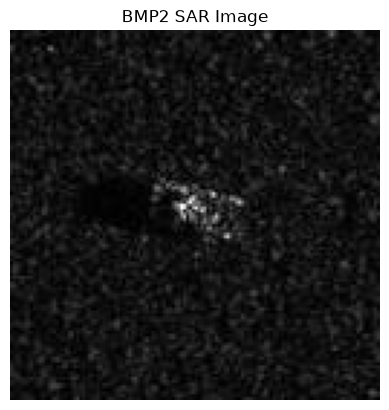

In [2]:

from PIL import Image
import matplotlib.pyplot as plt

# 找到 BMP2 类别中的第一张图片
image_path = next((train_dir / "BMP2").glob("*.jpg"))

# 读取图片
image = Image.open(image_path)

# 查看图片基本信息
print("图片路径：", image_path)
print("图片尺寸：", image.size)
print("图片模式：", image.mode)

# 显示图片
plt.imshow(image, cmap="gray")
plt.title("BMP2 SAR Image")
plt.axis("off")
plt.show()


In [3]:

import numpy as np

# 将刚才读取的图像转换成 NumPy 数组
image_array = np.array(image)

print("数组形状：", image_array.shape)
print("数据类型：", image_array.dtype)
print("最小像素值：", image_array.min())
print("最大像素值：", image_array.max())
print("左上角 5×5 的像素：")
print(image_array[:5, :5])


数组形状： (128, 128)
数据类型： uint8
最小像素值： 0
最大像素值： 255
左上角 5×5 的像素：
[[ 9 19 14  5 13]
 [28 27 12  6 22]
 [19 19  8  6 20]
 [ 0 10 12 11 12]
 [19 22 17 15 14]]


In [4]:

import torch

# 将 NumPy 数组转换成 PyTorch Tensor
image_tensor = torch.from_numpy(image_array)

print("Tensor 形状：", image_tensor.shape)
print("Tensor 数据类型：", image_tensor.dtype)
print("Tensor 设备：", image_tensor.device)


Tensor 形状： torch.Size([128, 128])
Tensor 数据类型： torch.uint8
Tensor 设备： cpu


In [5]:

# 将 Tensor 转换为32位浮点数
image_tensor = image_tensor.float()

print("转换后的数据类型：", image_tensor.dtype)
print("转换后的形状：", image_tensor.shape)
print("第一个像素值：", image_tensor[0, 0])


转换后的数据类型： torch.float32
转换后的形状： torch.Size([128, 128])
第一个像素值： tensor(9.)


In [6]:

# 增加通道维度
image_tensor = image_tensor.unsqueeze(0)
print("增加通道后：", image_tensor.shape)

# 增加批次维度
image_tensor = image_tensor.unsqueeze(0)
print("增加批次后：", image_tensor.shape)


增加通道后： torch.Size([1, 128, 128])
增加批次后： torch.Size([1, 1, 128, 128])


In [7]:

# 将像素值缩放到 0～1
normalized_tensor = image_tensor / 255.0

print("归一化前最小值：", image_tensor.min().item())
print("归一化前最大值：", image_tensor.max().item())

print("归一化后最小值：", normalized_tensor.min().item())
print("归一化后最大值：", normalized_tensor.max().item())

print("归一化后的形状：", normalized_tensor.shape)


归一化前最小值： 0.0
归一化前最大值： 255.0
归一化后最小值： 0.0
归一化后最大值： 1.0
归一化后的形状： torch.Size([1, 1, 128, 128])
